# 07 · Block F: analysis results
Reads the frozen results in `results/analysis/` (written by `inragwetrust.analysis`) and draws the paper figures at the template's text width. Nothing is recomputed here.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from inragwetrust.analysis import figures as fg
from inragwetrust.analysis import tables as tb

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results" / "analysis"
cls, WIDTH = fg.text_width(ROOT / "paper")
conf, sens = tb.load(RES)
pd.set_option("display.precision", 3)


def r(name: str) -> pd.DataFrame:
    return pd.read_csv(RES / f"{name}.csv")


print(f"Template {cls}, text width {WIDTH} in")

Template sn-jnl, text width 6.2 in


## Confirmatory tests (F1–F4), Holm-corrected within each family

In [2]:
cols = ["family", "model", "meta", "test", "block", "estimate_kind", "df", "estimate", "ci_low", "ci_high",
        "p_raw", "p_holm"]
pd.concat([d.reindex(columns=cols) for d in conf.values()], ignore_index=True).dropna(axis=1, how="all")

,family,model,meta,test,block,estimate_kind,df,estimate,ci_low,ci_high,p_raw,p_holm
0,F1,llama,NaN,NaN,NaN,OR rho 0->1,NaN,53.744,41.768,69.154,1.146e-210,3.439e-210
1,F1,mistral,NaN,NaN,NaN,OR rho 0->1,NaN,64.908,48.786,86.359,1.917e-180,3.834e-180
2,F1,qwen,NaN,NaN,NaN,OR rho 0->1,NaN,50.316,38.181,66.309,2.115e-170,2.115e-170
3,F2,llama,consistency,a,NaN,"delta ASR, rho>0",NaN,-0.024,-0.037,-0.011,5.630e-08,7.319e-07
4,F2,llama,consistency,b,NaN,"delta Acc, rho=0",NaN,-0.004,-0.036,0.028,9.007e-01,1.000e+00
5,F2,llama,consistency,c,NaN,"delta Abst, rho=0",NaN,0.044,0.024,0.066,1.131e-04,1.131e-03
6,F2,llama,reliability,a,NaN,"delta ASR, rho>0",NaN,-0.018,-0.032,-0.003,1.495e-04,1.346e-03
7,F2,llama,reliability,b,NaN,"delta Acc, rho=0",NaN,-0.034,-0.068,0.000,6.395e-02,3.764e-01
8,F2,llama,reliability,c,NaN,"delta Abst, rho=0",NaN,0.044,0.022,0.066,1.951e-04,1.561e-03
9,F2,mistral,consistency,a,NaN,"delta ASR, rho>0",NaN,-0.033,-0.046,-0.020,3.157e-21,5.367e-20


## Hypothesis verdicts (D250, D263)

In [3]:
pd.DataFrame(tb.verdict_rows(conf), columns=["hypothesis", "verdict", "evidence"])

,hypothesis,verdict,evidence
0,H1,partly supported,F1 significant for all three models; the steep...
1,H2,partly supported,5 of 6 $\Delta$ASR reductions significant; not...
2,H3,supported,Association only: flagged answers poisoned les...
3,H4,partly supported,4 of 4 interaction blocks significant; no cons...


## Figure 1 · Acc and ASR vs ρ (RQ1)

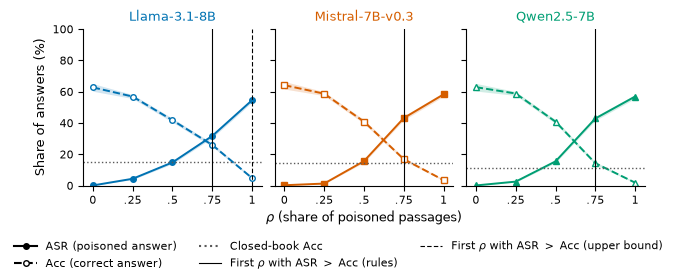

In [4]:
fig = fg.fig_rho_curves(r("descriptive_by_rho"), r("explore_crossover"), r("explore_closed_book"), WIDTH)

## Figure 2 · Meta-prompt minus plain (RQ2)

In [5]:
fig = fg.fig_prompt_effects(r("explore_prompt_effects"), WIDTH)

## Figure 3 · Flags above each model's own ρ = 0 rate (RQ3, association only)

In [6]:
fig = fg.fig_flag_baseline(r("explore_flag_baseline"), WIDTH)

## Figure 4 · ASR by poison type (RQ4)

In [7]:
fig = fg.fig_type_model(r("explore_type_model"), WIDTH)

## Figure 5 · Answers poisoned under plain: what the meta-prompt gives (exploratory)

In [8]:
fig = fg.fig_transitions(r("explore_transitions"), WIDTH)

## Robustness (exploratory): without flagged and without leak questions

In [9]:
summary, changed = tb.robustness_rows(sens)
display(pd.DataFrame(summary, columns=["family", "conclusions", "same without flagged", "same without leaks"]))
pd.DataFrame(changed, columns=["analysis", "test", "primary", "p_holm", "sensitivity", "p_holm_sens", "conclusion"])

,family,conclusions,same without flagged,same without leaks
0,F1/H1,3,3,3
1,F2/H2,18,18,16
2,F3/H3,3,3,3
3,F4/H4,4,4,4
4,Total,28,28,26


,analysis,test,primary,p_holm,sensitivity,p_holm_sens,conclusion
0,Leaks · F2,"Llama-3.1-8B, rel., $\Delta$ASR, $\rho>0$","$-$1.8 [$-$3.2, $-$0.3]",0.001,"$-$1.2 [$-$2.8, 0.3]",0.111,down $\to$ n.s.
1,Leaks · F2,"Mistral-7B-v0.3, cons., $\Delta$Acc, $\rho=0$","$-$4.2 [$-$7.0, $-$1.6]",0.032,"$-$3.7 [$-$7.0, $-$0.7]",0.181,down $\to$ n.s.
